   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

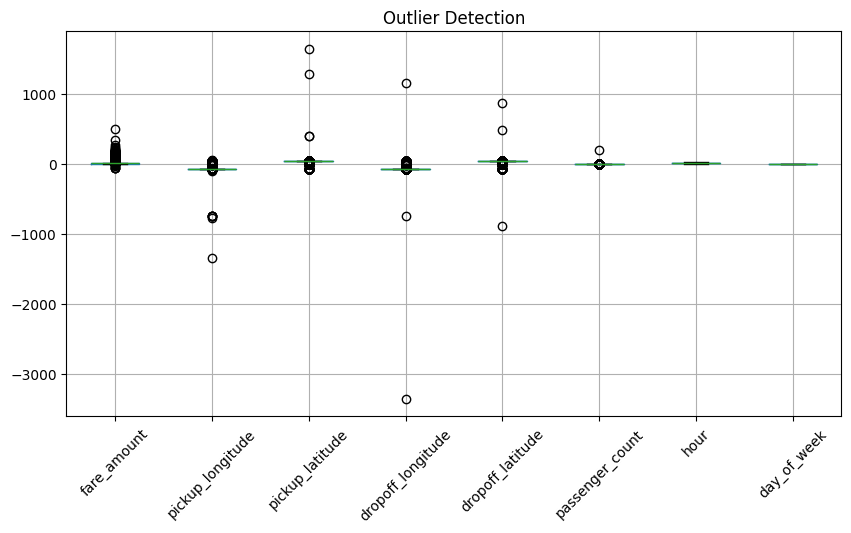


Correlation Matrix:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.010457        -0.008481   
pickup_longitude      0.010457          1.000000        -0.816461   
pickup_latitude      -0.008481         -0.816461         1.000000   
dropoff_longitude     0.008986          0.833026        -0.774787   
dropoff_latitude     -0.011014         -0.846324         0.702367   
passenger_count       0.010150         -0.000414        -0.001560   
hour                 -0.021473          0.002433        -0.003822   
day_of_week           0.007501          0.000825        -0.002455   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                 0.008986         -0.011014         0.010150   
pickup_longitude            0.833026         -0.846324        -0.000414   
pickup_latitude            -0.774787          0.702367        -0.001560   
dropoff_longitude           1.000000         -0.917010   

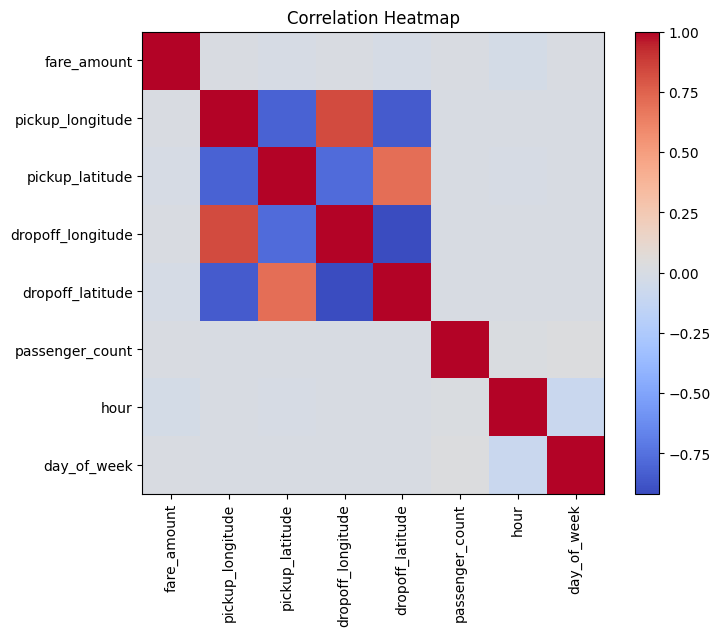

Linear Regression
R2 Score: 0.0007
RMSE: 10.31
----------------------
Ridge Regression
R2 Score: 0.0007
RMSE: 10.31
----------------------
Lasso Regression
R2 Score: 0.0003
RMSE: 10.31
----------------------


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.impute import SimpleImputer

# 1. Load and preprocess dataset
df = pd.read_csv("uber.csv")
print(df.head())

# Convert pickup_datetime into datetime
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
# Extract hour and day of week
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
# Drop unnecessary columns
df = df.drop(columns=['Unnamed: 0', 'key', 'pickup_datetime'])
# Handle missing values
imputer = SimpleImputer(strategy='mean')
df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
print("\nPreprocessed Dataset:")
print(df.head())

# 2. Identify outliers using boxplot
plt.figure(figsize=(10, 5))
df.boxplot()
plt.xticks(rotation=45)
plt.title("Outlier Detection")
plt.show()

# 3. Check correlation
corr = df.corr()
print("\nCorrelation Matrix:")
print(corr)
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

# 4. Split data into features and target
X = df.drop(columns=['fare_amount'])
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

# Lasso Regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

# 5. Evaluate and compare models
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(model_name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 2))
    print("----------------------")

evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
evaluate_model(y_test, y_pred_lasso, "Lasso Regression")